<a href="https://colab.research.google.com/github/wallstreetscott/hello-world/blob/master/Capstone_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# uploading dataset
from google.colab import files
uploaded = files.upload()

In [ ]:
# accessing data set
import pandas as pd
df = pd.read_csv('taxi_trip_pricing.csv')
df.tail()

,Trip_Distance_km,Time_of_Day,Day_of_Week,Passenger_Count,Traffic_Conditions,Weather,Base_Fare,Per_Km_Rate,Per_Minute_Rate,Trip_Duration_Minutes,Trip_Price
995,5.49,Afternoon,Weekend,4.0,Medium,Clear,2.39,0.62,0.49,58.39,34.4049
996,45.95,Night,Weekday,4.0,Medium,Clear,3.12,0.61,NaN,61.96,62.1295
997,7.70,Morning,Weekday,3.0,Low,Rain,2.08,1.78,NaN,54.18,33.1236
998,47.56,Morning,Weekday,1.0,Low,Clear,2.67,0.82,0.17,114.94,61.2090
999,22.85,Morning,Weekend,3.0,Medium,Clear,4.34,NaN,0.23,29.69,45.4437


In [ ]:
# find null values
df.isnull().sum()

NameError: name 'df' is not defined

In [ ]:
# fill in missing values

# fill in distance
average_miles = df['Trip_Distance_km'].mean()
df['Trip_Distance_km'] = df['Trip_Distance_km'].fillna(average_miles)

# fill in time of day
average_time = df['Time_of_Day'].mode()[0]
df['Time_of_Day'] = df['Time_of_Day'].fillna(average_time)

# fill in day
average_day = df['Day_of_Week'].mode()[0]
df['Day_of_Week'] = df['Day_of_Week'].fillna(average_day)

# fill in traffic conditions
average_traffic = df['Traffic_Conditions'].mode()[0]
df['Traffic_Conditions'] = df['Traffic_Conditions'].fillna(average_traffic)

# fill in passenger count
average_passenger = df['Passenger_Count'].mean()
df['Passenger_Count'] = df['Passenger_Count'].fillna(average_passenger)


# fill in weather
average_weather = df['Weather'].mode()[0]
df['Weather'] = df['Weather'].fillna(average_weather)


# fill in base fare
average_base = df['Base_Fare'].mean()
df['Base_Fare'] = df['Base_Fare'].fillna(average_base)

# fill in Per_Km_Rate
average_km = df['Per_Km_Rate'].mean()
df['Per_Km_Rate'] = df['Per_Km_Rate'].fillna(average_km)

#f fill in rate
average_rate = df['Per_Minute_Rate'].mean()
df['RaPer_Minute_Ratete'] = df['Per_Minute_Rate'].fillna(average_rate)

# fill in duration
average_duration = df['Trip_Duration_Minutes'].mean()
df['Trip_Duration_Minutes'] = df['Trip_Duration_Minutes'].fillna(average_duration)

# fill in price
average_price = df['Trip_Price'].mean()
df['Trip_Price'] = df['Trip_Price'].fillna(average_price)

average_per_minute = df['Per_Minute_Rate'].mean()
df['Per_Minute_Rate'] = df['Per_Minute_Rate'].fillna(average_per_minute)


# ensuring that code works
print("missing values per column")
print(df.isnull().sum())
df = df.dropna()


missing values per column
Trip_Distance_km         0
Time_of_Day              0
Day_of_Week              0
Passenger_Count          0
Traffic_Conditions       0
Weather                  0
Base_Fare                0
Per_Km_Rate              0
Per_Minute_Rate          0
Trip_Duration_Minutes    0
Trip_Price               0
RaPer_Minute_Ratete      0
dtype: int64


In [ ]:
# replacing words with numbers so AI can work

# replace time of day
df['Time_of_Day'] = df['Time_of_Day'].replace({'Morning': 1, 'Afternoon': 2, 'Evening': 3, 'Night':4})


# replace day of week
df['Day_of_Week'] = df['Day_of_Week'].replace({'Weekday':0, 'Weekend':1})

# replace traffic conditions
df['Traffic_Conditions'] = df['Traffic_Conditions'].replace({'Low':0, 'Medium':1, 'High':2})

# replce weather
df['Weather'] = df['Weather'].replace({'Sunny':0, 'Cloudy':1, 'Rain':2, 'Clear':3, 'Snow':4})


/tmp/ipython-input-3387066650.py:4: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Time_of_Day'] = df['Time_of_Day'].replace({'Morning': 1, 'Afternoon': 2, 'Evening': 3, 'Night':4})
/tmp/ipython-input-3387066650.py:8: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['Day_of_Week'] = df['Day_of_Week'].replace({'Weekday':0, 'Weekend':1})
/tmp/ipython-input-3387066650.py:11: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.in

In [ ]:
# importing libraries for linear regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score


# Independent and Dependent Variables
X = df.drop(columns = 'Trip_Price')
y = df['Trip_Price']

# training model and adding parameters
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


# testing model
model = LinearRegression()
model.fit(X_train, y_train)

# testing accuracy and precision
y_pred = model.predict(X_test)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("R2:", r2)
print("MSE:", mse)

R2: 0.7655542552259696
MSE: 194.6753157736572


In [ ]:
# importing libraries for logistic regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

# Convert continuous target to categories
# Example: Convert price to "Low", "Medium", "High"
y_discrete = pd.cut(y, bins=3, labels=['Low', 'Medium', 'High'])

# training and testing the model
X_train, X_test, y_train, y_test = train_test_split(
    X, y_discrete, test_size=0.2, random_state=42
)

model = LogisticRegression()
model.fit(X_train, y_train)

# testing accuracy and precision
y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy}")

Accuracy: 0.985


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
# importing libraries for linear regression
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression # Import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

# Ensure Day_of_Week is numerical before creating X and y
# This step is added to revert the changes made for plotting in a previous cell
df['Day_of_Week'] = df['Day_of_Week'].replace({'Weekday': 0, 'Weekend': 1})

# Drop 'log_total_sales' as it was created from 'Trip_Price' and causes data leakage.
# Also, the previous model wasn't trained with this feature.
if 'log_total_sales' in df.columns:
    df = df.drop(columns=['log_total_sales'])

# Independent and Dependent Variables
X = df.drop(columns = 'Trip_Price')
y = df['Trip_Price']

# training model and adding parameters
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

Scaler = StandardScaler()
X_train_scaled = Scaler.fit_transform(X_train)
X_test_scaled = Scaler.transform(X_test)

# Instantiate and fit a new LinearRegression model for this task
model_linear = LinearRegression()
model_linear.fit(X_train_scaled, y_train) # Fit with scaled data

y_pred = model_linear.predict(X_test_scaled) # Predict with scaled data
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("R2:", r2)
print("MSE:", mse)


R2: 0.7655542552259694
MSE: 194.67531577365736


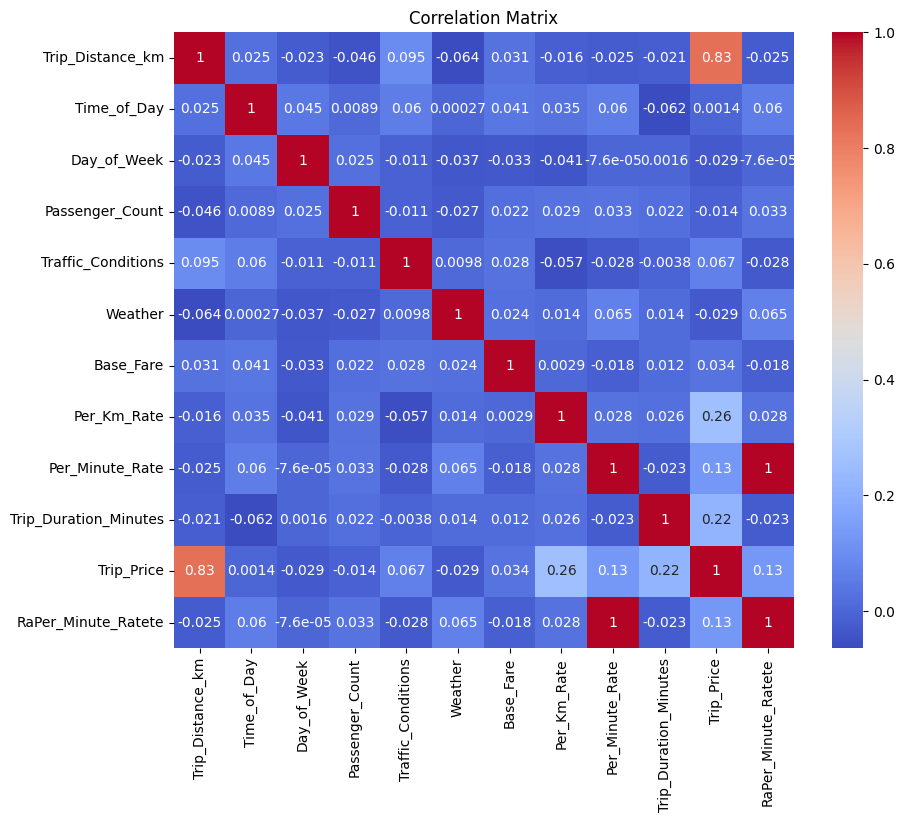

In [ ]:
# importing libraries for visuals
import matplotlib.pyplot as plt
import seaborn as sns

# referencing database
df_visuals = df

# making visuals
matrix = df_visuals.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(matrix, annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()


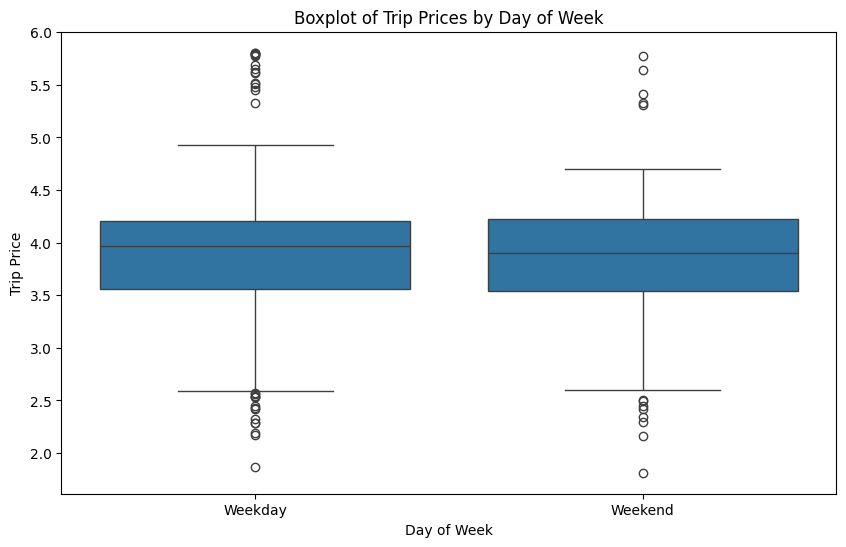

In [ ]:
#boxplot
import numpy as np
plt.figure(figsize=(10, 6))
df['log_total_sales'] = np.log(df['Trip_Price'])
df['Day_of_Week'] = df['Day_of_Week'].replace({0: 'Weekday', 1: 'Weekend'})
sns.boxplot(x='Day_of_Week', y='log_total_sales', data=df)


plt.title('Boxplot of Trip Prices by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Trip Price')
plt.show()

Text(0, 0.5, 'Frequency')

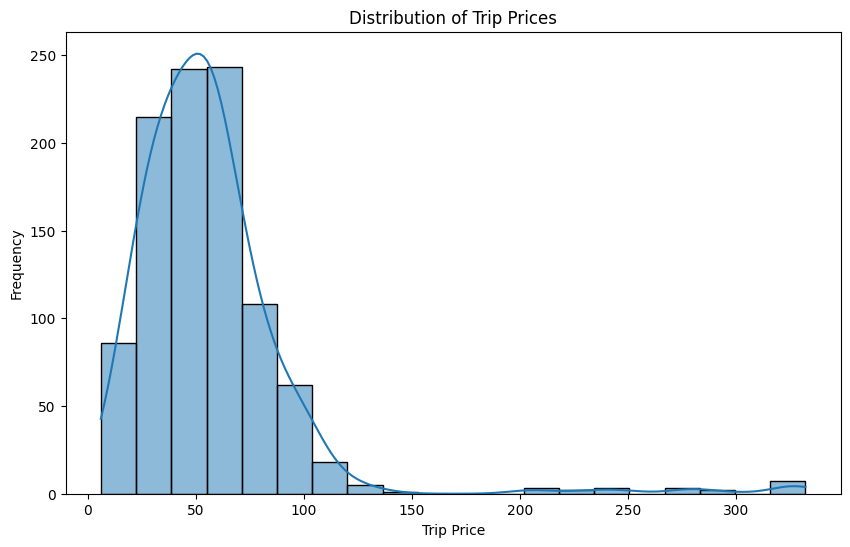

In [ ]:
# histogram
plt.figure(figsize=(10, 6))
sns.histplot(df['Trip_Price'], bins=20, kde=True)
plt.title('Distribution of Trip Prices')
plt.xlabel('Trip Price')
plt.ylabel('Frequency')